
# Wine Quality Modelling with Multilayer Perceptron (MLP)
**CSCI323 Group Project — Group FT4 | University of Wollongong**

The objective of this project is to create a model that can predict the quality of a wine given values from a physicochemical test. This will be a classification problem as the continuous values will be binned into: Low(0-4), Medium(5-7), High(8-10).

This notebook reproduces every experiment in the project report:
1. Load and preprocess the UCI Wine Quality dataset (red 1,599 samples)
2. Visualise data to understand overall data health and uncover hidden trends within each feature
> * Statistical Overview of data (pandas .info() and .describe())
> * Target distribution and most skewed feature
> * Heatmap to visualise features' correlation to target (wine quality)
> * Interaction of features, 2-Dimensional visualisation
> * In depth 3-Dimensional visualisation
3. Using domain knowledge acquired through research and uncovered trends through visualisation. The feature will be engineering and transformed to optimise the model's learning capabilities.
4. Compare 4 baseline model: 2 basic model (Logistic Regression, Decision Tree) and 2 advanced model (MLP, Random Forest) based on Scoring metrics:
> * Accuracy
> * Precision
> * Recall
> * F1-Score
5. Pick the best performing model to train, hyper tune the parameters and test using the same metrics


In [ ]:
import os
import urllib.request

os.makedirs('data', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

# UCI Wine Quality dataset (legacy mirror + GitHub fallback)
urls = {
    'data/winequality-red.csv': [
        'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv',
        'https://raw.githubusercontent.com/faridm1/Wine-Quality/master/winequality-red.csv'
    ]}
for path, cands in urls.items():
    if not os.path.exists(path):
        for url in cands:
            try:
                print('Downloading', path, 'from', url)
                urllib.request.urlretrieve(url, path)
                break
            except Exception as e:
                print('  failed:', e)
    print(path, os.path.getsize(path), 'bytes')

data/winequality-red.csv 84199 bytes


# 1. Data Preprocessing

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


# ===============================================
# 1. Loading data to visualise data and analyse
# ===============================================
df = pd.read_csv("data/winequality-red.csv", sep=";")

df.info()
df.describe().round(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.00000,1599.00000,1599.00000,1599.00000,1599.00000,1599.00000,1599.00000,1599.00000,1599.00000,1599.00000,1599.00000,1599.00000
mean,8.31964,0.52782,0.27098,2.53881,0.08747,15.87492,46.46779,0.99675,3.31111,0.65815,10.42298,5.63602
std,1.74110,0.17906,0.19480,1.40993,0.04707,10.46016,32.89532,0.00189,0.15439,0.16951,1.06567,0.80757
min,4.60000,0.12000,0.00000,0.90000,0.01200,1.00000,6.00000,0.99007,2.74000,0.33000,8.40000,3.00000
25%,7.10000,0.39000,0.09000,1.90000,0.07000,7.00000,22.00000,0.99560,3.21000,0.55000,9.50000,5.00000
50%,7.90000,0.52000,0.26000,2.20000,0.07900,14.00000,38.00000,0.99675,3.31000,0.62000,10.20000,6.00000
75%,9.20000,0.64000,0.42000,2.60000,0.09000,21.00000,62.00000,0.99784,3.40000,0.73000,11.10000,6.00000
max,15.90000,1.58000,1.00000,15.50000,0.61100,72.00000,289.00000,1.00369,4.01000,2.00000,14.90000,8.00000


# 2. Exploratory Data Analysis & Class Distribution
## Dashboard 1: Exploratory Data Analysis Overview
> 1. **Target Distribution (Wine Quality)**: Histogram distribution of wine quality scores (3 to 8), class imbalance in middle (5 and 6).
> 2. **Residual Sugar Skewness (Log Scale)**: Log-scaled histogram with a kernel density estimate (KDE) to show the right-skewed distribution of residual sugar levels.
> 3. **Alcohol Content Distribution by Target**: Box plots to see the spread and median alcohol percentage for each wine rating.

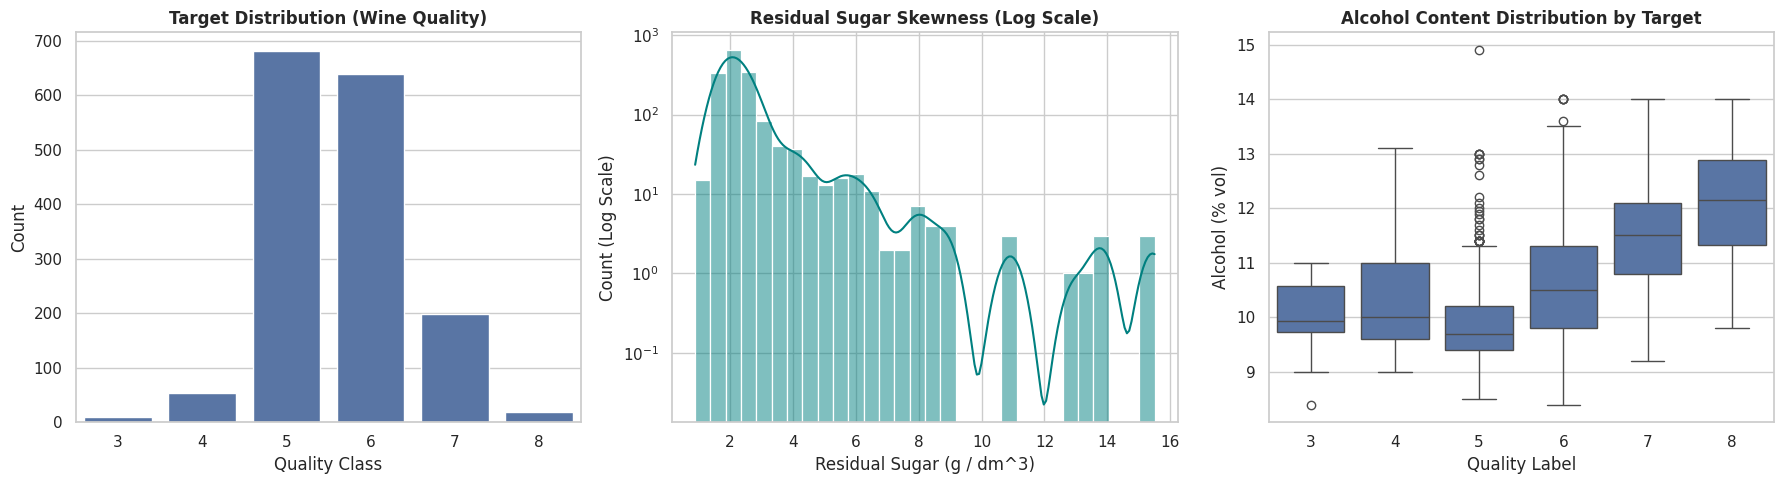

In [ ]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Target Distribution (Bar plot)
sns.countplot(data=df, x='quality', ax=axes[0])
axes[0].set_title('Target Distribution (Wine Quality)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Quality Class')
axes[0].set_ylabel('Count')

# Subplot 2: Skewed Continuous Feature Distribution with KDE (Log Scale) - Residual Sugar
sns.histplot(data=df, x='residual sugar', kde=True, ax=axes[1], color="teal", bins=30)
axes[1].set_yscale('log')
axes[1].set_title('Residual Sugar Skewness (Log Scale)', fontweight='bold')
axes[1].set_xlabel('Residual Sugar (g / dm^3)')
axes[1].set_ylabel('Count (Log Scale)')

# Subplot 3: Alcohol Distribution by Quality Target (Box Plot)
sns.boxplot(data=df, x='quality', y='alcohol', ax=axes[2],)
axes[2].set_title('Alcohol Content Distribution by Target', fontweight='bold')
axes[2].set_xlabel('Quality Label')
axes[2].set_ylabel('Alcohol (% vol)')

plt.tight_layout()

## 2. Heatmap / Correlation
Correlation Heatmap: Strong linear relationships in citric acid VS fixed acidity (+0.67) and volatile acidity VS density (-0.39).

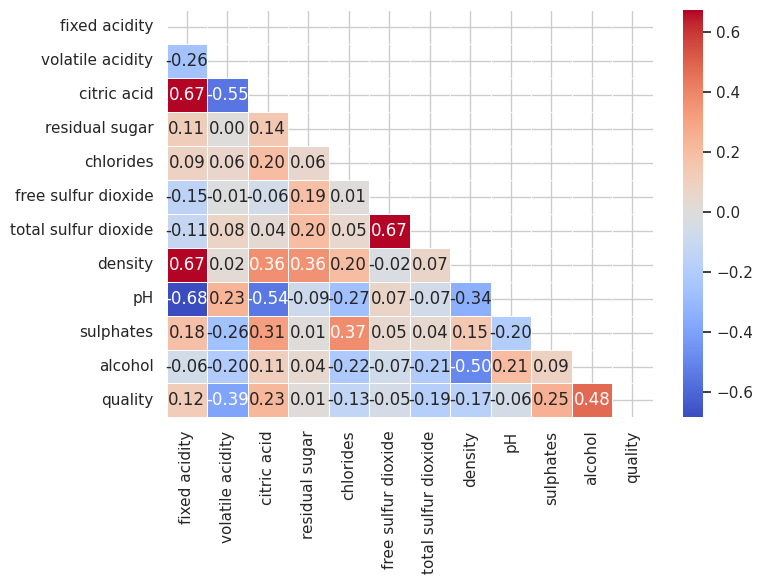

In [ ]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
    mask=np.triu(corr), linewidths=0.5,)

plt.tight_layout()
plt.show()

## Dashboard 3: Hidden Patterns & Attribute Dynamics Dashboard
> 1. **Feature Correlation with Wine Quality**: Correlation coefficient ranking of chemical attributes to wine quality, Only alcohol has most noticable positve corelation to target and volatile acidity is the strongest negative predictor.
> 2. **Volatile Acidity vs Alcohol**: A 2D scatter plot mapping alcohol against volatile acidity.
> 3. **Average Alcohol Content by Quality Category**: Horizontal bar chart to see the percentage across binned target classes (low, medium, high).
> 4. **Quality Score by Sulphates Quartile**: A grouped bar chart tracking wine quality scores across sulphates quartiles (Q1–Q4), showing high sulphate brackets lead to higher wine quality.
> 5. **Citric Acid Across Quality Scores**: A line chart showing that higher-quality wines consistently have more citric acid, with a shaded band showing the range of uncertainty.
> 6. **Density Distribution by Quality Category**: Visualising box plots again to see the spread and median alcohol percentage for new wine rating (low, mediu, high).

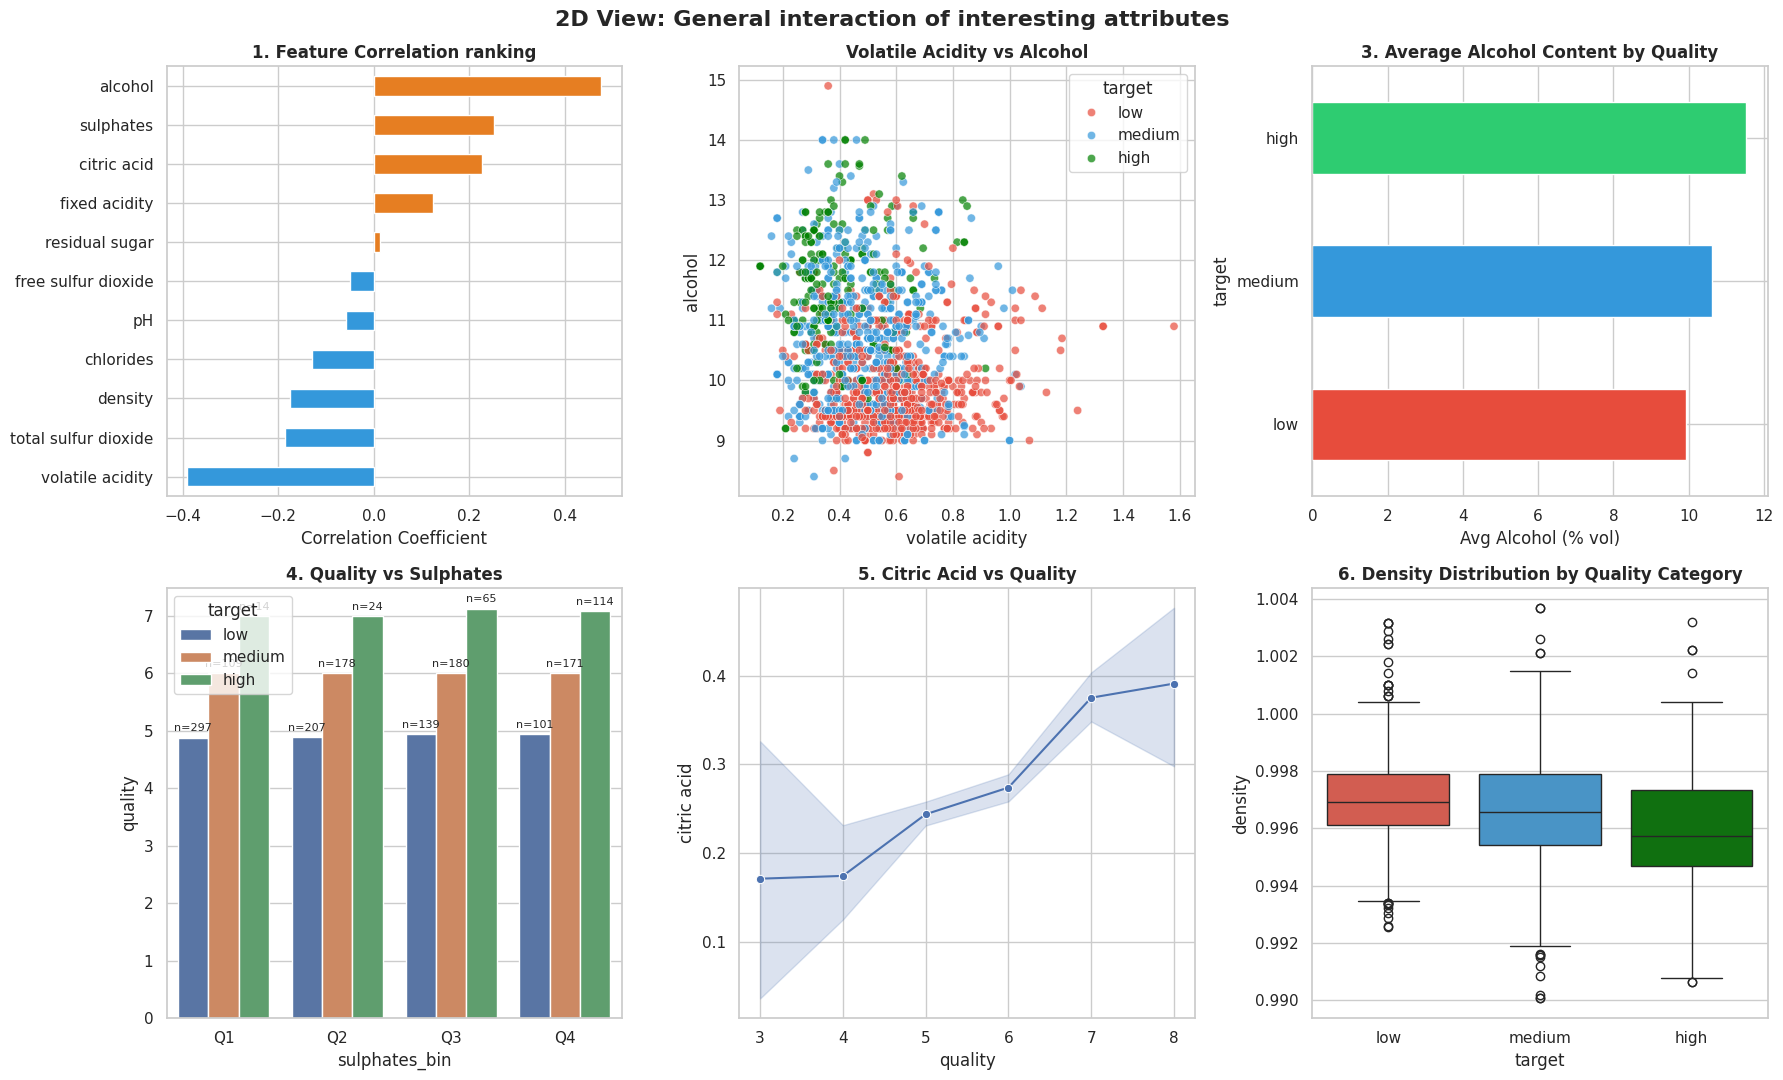

In [ ]:
bins = [0, 5, 6, 10]
labels = ["low", "medium", "high"]
df["target"] = pd.cut(df["quality"], bins=bins, labels=labels)

# Original feature to visualise
features = [col for col in df.columns if col not in ["quality", "target", "sulphates_bin"]]

# 2. Dashboard 2
fig = plt.figure(figsize=(18, 11))
fig.suptitle("2D View: General interaction of interesting attributes", fontsize=16, fontweight="bold",)

target_palette = {"low": "#E74C3C", "medium": "#3498DB", "high": "green"}

# Subplot 1: Feature Correlation Ranking with Quality
ax_corr = plt.subplot2grid((2, 3), (0, 0))
corr_target = df[features].corrwith(df["quality"]).sort_values()
colors = ["#3498DB" if x < 0 else "#E67E22" for x in corr_target.values]
corr_target.plot(kind="barh", color=colors, ax=ax_corr)
ax_corr.set_title("1. Feature Correlation ranking", fontweight="bold")
ax_corr.set_xlabel("Correlation Coefficient")

# Subplot 2: Interaction: Volatile Acidity vs Alcohol (3 Target Bins)
ax_scat = plt.subplot2grid((2, 3), (0, 1))
sns.scatterplot(data=df, x="volatile acidity", y="alcohol",
    hue="target", palette=target_palette, alpha=0.7, ax=ax_scat,)

ax_scat.set_title("Volatile Acidity vs Alcohol", fontweight="bold")

# Subplot 3: Average Alcohol Content across 3 Target Categories
ax_top = plt.subplot2grid((2, 3), (0, 2))
top_bottom = df.groupby("target", observed=False)["alcohol"].mean().loc[
    ["low", "medium", "high"]]

top_bottom.plot(kind="barh", color=["#E74C3C", "#3498DB", "#2ECC71"], ax=ax_top)
ax_top.set_title("3. Average Alcohol Content by Quality", fontweight="bold")
ax_top.set_xlabel("Avg Alcohol (% vol)")

# Subplot 4: Quality Score by Sulphates Quartile
ax_bar = plt.subplot2grid((2, 3), (1, 0))
df["sulphates_bin"] = pd.qcut(df["sulphates"], 4, labels=["Q1", "Q2", "Q3", "Q4"])

sns.barplot(data=df, x="sulphates_bin", y="quality",
    ax=ax_bar, errorbar=None, hue = "target")

# 1. Calculate sample counts for each (sulphates_bin, target) pair
counts = df.groupby(["sulphates_bin", "target"], observed=False).size().unstack()

# 2. Add count labels (n=...) to the top of each bar container
for i, container in enumerate(ax_bar.containers):
    target_name = counts.columns[i]
    labels = [f"n={c}" for c in counts[target_name]]
    ax_bar.bar_label(container, labels=labels, padding=3, fontsize=8)

ax_bar.set_title("4. Quality vs Sulphates", fontweight="bold")

# Subplot 5: Citric Acid Trend across Raw Quality Ratings
ax_line = plt.subplot2grid((2, 3), (1, 1))
sns.lineplot(data=df, x="quality", y="citric acid",
    marker="o", ax=ax_line,)

ax_line.set_title("5. Citric Acid vs Quality", fontweight="bold")

# Subplot 6: Density Distribution Boxplot across 3 Target Categories
ax_box = plt.subplot2grid((2, 3), (1, 2))
sns.boxplot(data=df, x="target", y="density", hue="target",
    ax=ax_box, palette=target_palette,)

ax_box.set_title("6. Density Distribution by Quality Category", fontweight="bold")

plt.tight_layout()
plt.show()

## Dashboard 4: Wine Quality Deep-Dive Analysis Dashboard
> 1. **Normalized Attribute Signal Divergence (%)**: A graph comparing four main trait for quality of wines to show what makes good wine stand out.
> 2. **Simplified 2D Latent Biplot & Density Contours**: A 2D map that condenses the wine ingredients into two main combinations, showing where low, medium, and high-quality wines overlap and where they group separately.
> 3. **Quality Matrix, Volatile Acidity vs Alcohol (Mean Quality Score)**: A 2D quantile heatmap displaying mean quality ratings across combined alcohol and volatile acidity brackets. This visualisation shows that high alcohol (>11.1%) combined with low volatile acidity (<0.39) leads to the higher wine quality (6.50).

> `Plotting too many feature into one axis makes visualising the chart difficult. PCA solves this by grouping feature into PC1(Principal Component 1) most important combination of ingredient and PC2(Principal Component 2) second most important `

/tmp/ipykernel_2670/438020499.py:76: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  risk_matrix = df.pivot_table(


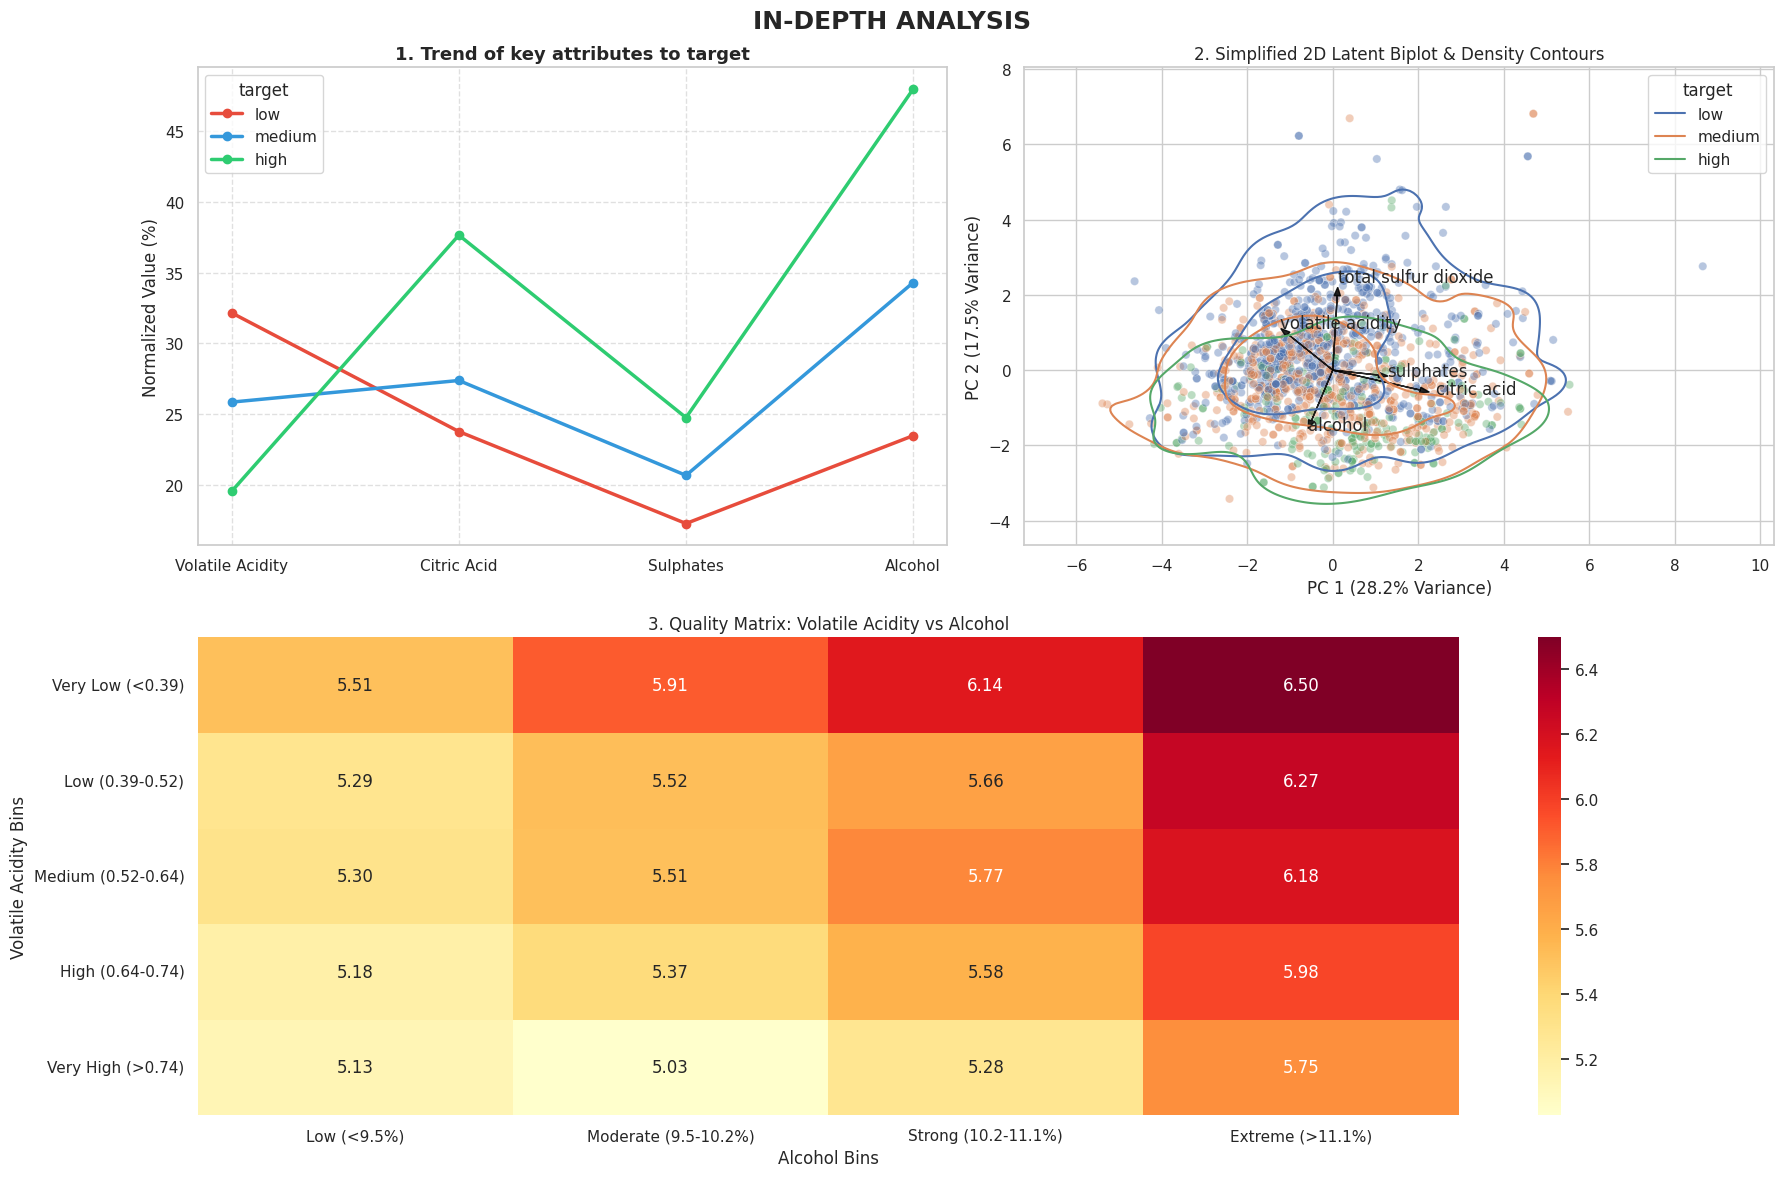

In [ ]:
# Set aesthetic style
sns.set_theme(style="whitegrid")

# 2. Build Deep-Dive Dashboard 4
fig = plt.figure(figsize=(18, 12))
fig.suptitle("IN-DEPTH ANALYSIS", fontsize=18, fontweight="bold",)

# Subplot 1: Visualising quality trend of key attributes
ax1 = plt.subplot2grid((2, 2), (0, 0))
drivers = ["volatile acidity", "citric acid", "sulphates", "alcohol"]

norm_df = (df[drivers]-df[drivers].min())/(df[drivers].max()-df[drivers].min())

norm_df["target"] = df["target"]
divergence = norm_df.groupby("target", observed=False)[drivers].mean().T * 100

divergence[["low", "medium", "high"]].plot(marker="o", linewidth=2.5,
    ax=ax1, color=["#E74C3C", "#3498DB", "#2ECC71"],)

ax1.set_title("1. Trend of key attributes to target",
    fontsize=13, fontweight="bold",)

ax1.set_ylabel("Normalized Value (%)")
ax1.set_xticks(range(len(drivers)))
ax1.set_xticklabels(["Volatile Acidity", "Citric Acid", "Sulphates", "Alcohol"])
ax1.grid(True, linestyle="--", alpha=0.6)


# Subplot 2: 2D PCA Analysis, identifying Primary and Secondary drivers
ax2 = plt.subplot2grid((2, 2), (0, 1))

# Scaling features
X_scaled = StandardScaler().fit_transform(df[features])
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(X_scaled)

df["PC1"] = pca_coords[:, 0]
df["PC2"] = pca_coords[:, 1]

# 1. KDE Plot to visualise contours
# 2. Scatter Plot to visualise data points
sns.kdeplot(data=df, x="PC1", y="PC2", hue="target", levels=3, ax=ax2)
sns.scatterplot(data=df, x="PC1", y="PC2", hue="target", alpha=0.4, ax=ax2, legend=False)

# 3. Arrows & Text Labels
drivers = ["alcohol", "volatile acidity", "citric acid",
                    "sulphates", "total sulfur dioxide",]

loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

for i, feature_name in enumerate(features):
    if feature_name in drivers:
        x_arrow = loadings[i, 0] * 2.5
        y_arrow = loadings[i, 1] * 2.5
        ax2.arrow(0, 0, x_arrow, y_arrow, color="black",alpha=0.85, head_width=0.15,)
        ax2.text(x_arrow * 1.18, y_arrow * 1.18, feature_name)

pc1 = pca.explained_variance_ratio_[0] * 100
pc2 = pca.explained_variance_ratio_[1] * 100

ax2.set_title("2. Simplified 2D Latent Biplot & Density Contours")
ax2.set_xlabel(f"PC 1 ({pc1:.1f}% Variance)")
ax2.set_ylabel(f"PC 2 ({pc2:.1f}% Variance)")


# Subplot 3: Quality Matrix Heatmap (Volatile Acidity vs Alcohol)
ax3 = plt.subplot2grid((2, 2), (1, 0), colspan=2)

# Binning features
df["alcohol_bin"] = pd.qcut(df["alcohol"], q=4, labels=[
    "Low (<9.5%)", "Moderate (9.5-10.2%)", "Strong (10.2-11.1%)","Extreme (>11.1%)",],)
df["vol_acidity_bin"] = pd.qcut(df["volatile acidity"], q=5, labels=["Very Low (<0.39)",
    "Low (0.39-0.52)", "Medium (0.52-0.64)", "High (0.64-0.74)","Very High (>0.74)",],)

# Matrix plot
risk_matrix = df.pivot_table(
    index="vol_acidity_bin", columns="alcohol_bin", values="quality", aggfunc="mean")

# Heatmap plot
sns.heatmap(risk_matrix, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax3)

# Axis labels & Title
ax3.set_title("3. Quality Matrix: Volatile Acidity vs Alcohol")
ax3.set_xlabel("Alcohol Bins")
ax3.set_ylabel("Volatile Acidity Bins")

plt.tight_layout()
plt.show()

# 3. Data Preprocessing & Feature Engineering
Reloading the data to ensure data integrity as the feaures were manipulated to crate the visualisation.
1. **Total acidity**: Aggregates the overall acidity to represent the overall acidic profile of the wine. This will help tree splits or linear models evaluate total acidic strength and treat the 2 features independently.
2. **Sulfur Dioxide Derivatives**: Subtracting active preservatives from total sulfur gives us the bound preservatives, this shows what percentage is actively protecting the wine measuring how stable and well-preserved the wine is, regardless of the overall liquid volume.
3. **Flavor Balance**: Captures the balance of the wine in a single ratio, providing a strong domain-specific signal that directly correlates with sensory quality scores.
4. **Sacling (log transformation)**: Residual sugar and chlorides are heavily right skewed. Compressing the the right tail will adress the extreme ouliers. This will reduce the distorting influence on the model and help the linear algorithms.
5. **Target binning**: Since most wines in the first dashboard are grouped in categories 5 and 6, we adjusted the group boundaries to Low (0–5), Medium (6), and High (7–10) to create a much more balanced dataset.





In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split


# ==========================================
# 2. Data Preperation
# ==========================================

# 1. Reload data to ensures data integrity and prevents
#     permanent information loss after filtering or transformation.
df = pd.read_csv("data/winequality-red.csv", sep=";")

# 1. Acid Ratio (Volatile / Fixed)
df["total_acidity_ratio"] = df["volatile acidity"] / (df["fixed acidity"] + 1e-5)
df["total_acidity"] = df["fixed acidity"] + df["volatile acidity"]

# 2. Sulfur Dioxide Derivatives
df["bound_sulfur_dioxide"] = df["total sulfur dioxide"] - df["free sulfur dioxide"]
df["free_so2_ratio"] = df["free sulfur dioxide"] / (df["total sulfur dioxide"] + 1e-5)

# 3. Flavor Balance (Sugar-to-Acid Ratio)
df["sugar_to_acid_ratio"] = df["residual sugar"] / (df["total_acidity"] + 1e-5)

# 4. Log Transformations for Skewed Features
df["log_residual_sugar"] = np.log1p(df["residual sugar"])
df["log_chlorides"] = np.log1p(df["chlorides"])

# Bin Quality Scores into Multi-Class Categories: low (1-5), medium (6), high (7-10)
df["target"] = pd.cut(df["quality"], bins=[0, 5, 6, 10], labels=["low", "medium", "high"])

# Separate Data (X) and Target (y)
X = df.drop(columns=["quality", "target"]).select_dtypes(include=[np.number])
y = df["target"]


# 2. STRATIFIED SPLIT & SCALING
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. 4 baseline model comparison
## Evaluation Metrics
- Accuracy: Measures the overall proportion of correct predictions across all classes.

`Accuracy = (TP + FN) / (TP + TN + FP + FN)`

- Precision (Macro): Calculates the average proportion of correct positive predictions for each class, treating all classes equally regardless of sample size.

`Precision = TP / (TP + FP)`

- Recall (Macro): Calculates the average proportion of actual class instances correctly identified by the model across all categories.

`Recall = TP / (TP + FN)`

- F1-Score (Macro): The unweighted harmonic mean of Macro Precision and Macro Recall, ensuring minority classes are evaluated fairly without being overshadowed by larger classes.
- F1-Score (Weighted): Computes the average F1-score across all classes, weighted by the sample support of each category.

`F1 = (Precision * Recall) / (Precision + Recall)`

## Baseline models
- Logistic Regression: A linear model that predicts class probabilities using a weighted combination of input features.
- Multi-Layer Perceptron (MLP): A feedforward neural network capable of learning non-linear patterns through hidden layer representations.
- Decision Tree: A non-parametric model that splits data based on feature thresholds.
- Random Forest: An ensemble of decision trees trained on random data and feature subsets.



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


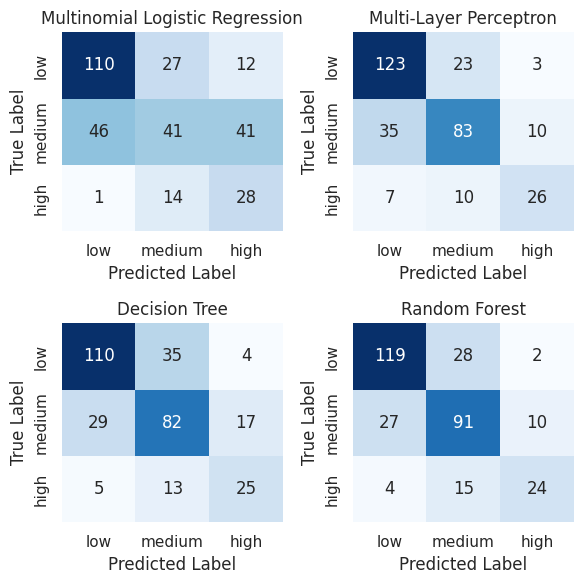

=== Baseline Model Perfomrance ===
                          Model  Accuracy  Precision (Macro)  Recall (Macro)  F1 (Macro)  F1 (Weighted)
                  Random Forest  0.731250           0.713035        0.689245    0.699413       0.730139
         Multi-Layer Perceptron  0.725000           0.709213        0.692864    0.699305       0.722134
                  Decision Tree  0.678125           0.646045        0.653425    0.649437       0.679371
Multinomial Logistic Regression  0.559375           0.515439        0.569910    0.520348       0.551639


In [ ]:
# ==========================================
# 3. Baseline Models and Hypertuning
# ==========================================
models = {
    "Multinomial Logistic Regression": LogisticRegression(multi_class="multinomial", max_iter=1000, random_state=42, class_weight="balanced"),
    "Multi-Layer Perceptron": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced_subsample"),}

metrics_list = []
class_labels = ["low", "medium", "high"]
fig, axes = plt.subplots(2, 2, figsize=(6,6))

# Confusion matrix to plot for each model
for ax, (name, model) in zip(axes.flat, models.items()):
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    # Recording results for each model
    metrics_list.append({"Model": name, "Accuracy": report["accuracy"],
        "Precision (Macro)": report["macro avg"]["precision"],
        "Recall (Macro)": report["macro avg"]["recall"],
        "F1 (Macro)": report["macro avg"]["f1-score"],
        "F1 (Weighted)": report["weighted avg"]["f1-score"],})
    # Confusion matrix plot
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=class_labels, yticklabels=class_labels)
    ax.set(title=name, xlabel="Predicted Label", ylabel="True Label")

plt.tight_layout()
plt.show()

performance_df = pd.DataFrame(metrics_list).sort_values(by="F1 (Macro)", ascending=False)
print("=== Baseline Model Perfomrance ===")
print(performance_df.to_string(index=False))



# 5.  Training and Hypertuning best model (Random Forest)
- **Random Forest**: An ensemble learning algorithm that combines multiple decision trees constructed on random data subsets through bagging and random feature subsets to produce a stable, highly generalized prediction.
- **GridSearch**:
> - 5-fold cross validation with 48 hyperparameters (Total fits = 5 * 48 = 240 fits)
> - **Optimal settings**: max_depth = 15, max_features = 'sqrt', min_samples_leaf = 1, min_samples_split = 2, and n_estimators = 100
- **Result Summary**
> - **Overall Accuracy & Macro Average**: Overall accuracy of 0.61 and a Macro F1-score of 0.52 (Macro Precision: 0.75, Macro Recall: 0.51)
> - **Class break down**: The model perfectly identifies low quality wines when predicted (1.00 precision) and catches nearly all medium wines (0.98 recall), but struggles to consistently isolate the rare high quality tier (0.42 F1-score).
> - **Top Feature Driver**: **<u>Alcohol</u>** is the single strongest predictor of wine quality, followed closely by **<u>sulphates and volatile acidity</u>**, and engineered **<u>sulfur dioxide ratios</u>**.


Overall, the model did well as F1-scoreis higher, F1-score balances precision and recall to fairly measure performance across all classes, whereas accuracy easily masks a model's total failure on minority classes when datasets are severely imbalanced.

=== Starting Hyperparameter Tuning ===

Best Parameters Found: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

=== OPTIMIZED RANDOM FOREST PERFORMANCE ===
              precision    recall  f1-score   support

        high       0.60      0.56      0.58        43
         low       0.81      0.82      0.82       149
      medium       0.70      0.71      0.71       128

    accuracy                           0.74       320
   macro avg       0.70      0.70      0.70       320
weighted avg       0.74      0.74      0.74       320



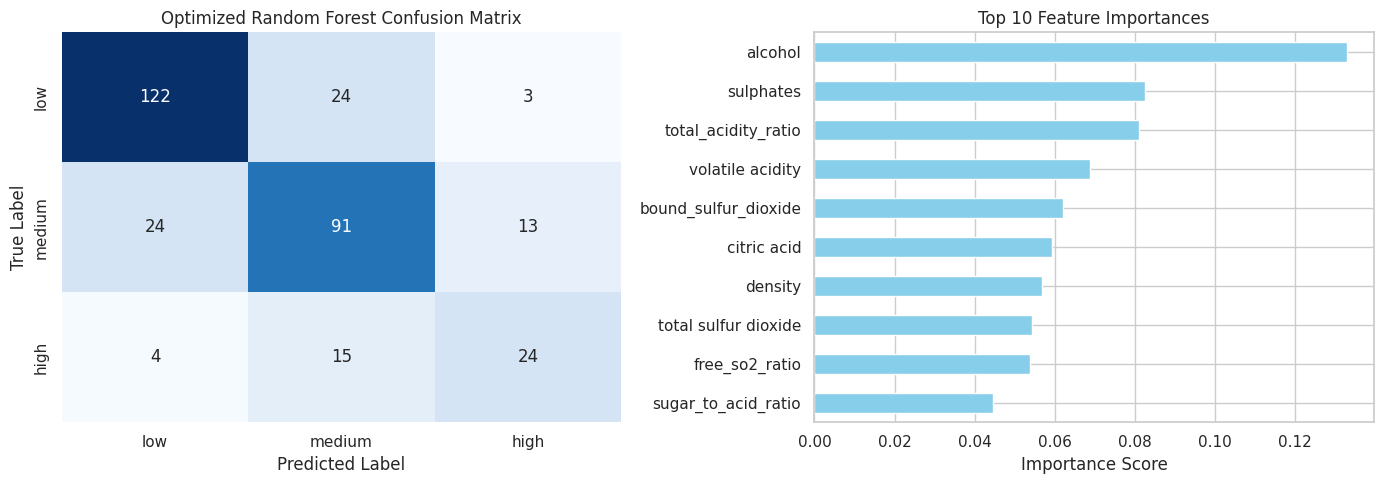

In [ ]:
# Hyper parameters to optimise
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],}

rf_base = RandomForestClassifier(random_state=42, class_weight="balanced_subsample")
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(estimator=rf_base, param_grid=param_grid,
    cv=cv_strategy, scoring="f1_macro", n_jobs=-1,)

print("=== Starting Hyperparameter Tuning ===")
grid_search.fit(X_train_scaled, y_train)

best_rf = grid_search.best_estimator_
print("\nBest Parameters Found:", grid_search.best_params_)


# 2. Testing model using train data
y_pred = best_rf.predict(X_test_scaled)
class_labels = ["low", "medium", "high"]

print("\n=== OPTIMIZED RANDOM FOREST PERFORMANCE ===")
print(classification_report(y_test, y_pred, zero_division=0))


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix plot
cm_opt = confusion_matrix(y_test, y_pred, labels=class_labels)
sns.heatmap(cm_opt, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False,
    xticklabels=class_labels, yticklabels=class_labels,)

axes[0].set(title="Optimized Random Forest Confusion Matrix",
    xlabel="Predicted Label", ylabel="True Label",)

# Feature importance plot
importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values()
importances.tail(10).plot(kind="barh", ax=axes[1], color="skyblue")
axes[1].set(title="Top 10 Feature Importances", xlabel="Importance Score")

plt.tight_layout()
plt.show()